<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 10 · Uncertainty</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Least squares predicts the conditional mean. A plan that has to survive a heavy or a light week needs ranges, and quantile regression produces them by predicting conditional quantiles directly: swap the squared error for the pinball loss at level $\tau$, and the fitted model sits above a fraction $\tau$ of the data. On synthetic harvest data whose spread grows with the area picked, a linear 10th-to-90th percentile band widens from $7.4$ to $37.2$ tonnes across the range, while a mean $\pm$ constant band holds 84% of new weeks overall but 99% of small ones and 65% of large ones. Gradient boosting with `loss="quantile"` follows a seasonal peak, at a price. Quantiles fitted separately cross: half the held-out rows had at least one out of order, fixed by sorting. And a model that covered 76% of its training rows covered 64.5% of unseen fields until it was regularised. Afterwards you should be able to fit linear and boosted quantile models in scikit-learn, repair crossings, and check coverage on held-out data, overall and by group.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, QuantileRegressor
from sklearn.metrics import mean_pinball_loss

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)

## From the mean to a quantile

[Least squares](../least-squares.qmd) chooses the line that minimises the sum of squared residuals, and the answer is a model of the conditional mean: the average $y$ at each $x$. A packhouse planning labour for next week needs more than the average. It needs a figure it will exceed only one week in ten, and one it will fall short of only one week in ten.

Those figures are **conditional quantiles**. The $\tau$-quantile $q_\tau(x)$ is the value below which a fraction $\tau$ of outcomes fall, among cases with features $x$; $q_{0.5}$ is the median, and $[q_{0.1}, q_{0.9}]$ is an 80% interval. Quantile regression, introduced by Koenker and Bassett[^1], fits $q_\tau(x)$ directly, by changing the loss. Least squares charges $u^2$ for a residual $u$; quantile regression charges the **pinball loss**

$$L_\tau(y, \hat{y}) = \max\left(\tau u,\; (\tau - 1)\,u\right), \qquad u = y - \hat{y}$$

where $y$ is the observed value, $\hat{y}$ the model's prediction and $u$ the residual, all in the target's units (here tonnes), and $\tau \in (0, 1)$ is the chosen quantile level, dimensionless. An under-prediction ($u > 0$) costs $\tau$ per tonne and an over-prediction costs $1 - \tau$ per tonne. At $\tau = 0.5$ the two costs are equal, $L_{0.5} = |u|/2$, and the method is the least-absolute-deviations fit from the least-squares module. Koenker and Hallock describe the general case as an asymmetrically weighted sum of absolute errors[^2].

Why the minimum lands on the quantile takes one line. Raise every prediction by a small amount $\delta$. Each of the $n_\text{below}$ points below the fit costs $(1 - \tau)\delta$ more, and each of the $n_\text{above}$ points above it costs $\tau\delta$ less. The total changes by $\delta\left[(1 - \tau)\,n_\text{below} - \tau\, n_\text{above}\right]$, which is zero only when $n_\text{below} / (n_\text{below} + n_\text{above}) = \tau$. At the optimum, a fraction $\tau$ of the training points sit below the fit.

The same loss scores quantile forecasts after the fact; [Pinball loss and quantiles](../pinball-loss-and-quantiles.qmd) covers that side. This module is about producing them.

## A straight line for each quantile

The first data set is synthetic. Each row is one week on a farm: $h$ hectares picked, between 5 and 50, and the tonnes harvested, $h$ times a yield drawn from a normal distribution with mean $1.2$ and standard deviation $0.3\text{ t ha}^{-1}$. The noise is in the yield, so the spread in tonnes grows in proportion to the area, and every true quantile is a straight line through the origin, $q_\tau(h) = (1.2 + 0.3\, z_\tau)\, h$, where $z_\tau$ is the $\tau$-quantile of the standard normal distribution.

scikit-learn's `QuantileRegressor` fits one line per $\tau$ by linear programming. Its L1 penalty is on by default, so set `alpha=0` for plain quantile regression:

In [2]:
def harvest(n):
    """Synthetic weeks: hectares picked, and tonnes = hectares x yield, yield ~ N(1.2, 0.3) t/ha."""
    ha = rng.uniform(5, 50, n)
    return ha, ha * rng.normal(1.2, 0.3, n)


ha, tonnes = harvest(400)
X = ha.reshape(-1, 1)

TAUS = (0.1, 0.5, 0.9)
# alpha=0 turns off the L1 penalty, which is on by default (alpha=1) and shrinks the slope.
qr = {tau: QuantileRegressor(quantile=tau, alpha=0).fit(X, tonnes) for tau in TAUS}
ols = LinearRegression().fit(X, tonnes)

pd.DataFrame(
    {
        "intercept (t)": [ols.intercept_] + [qr[tau].intercept_ for tau in TAUS],
        "slope (t/ha)": [ols.coef_[0]] + [qr[tau].coef_[0] for tau in TAUS],
        "true slope (t/ha)": [1.2] + [1.2 + 0.3 * norm.ppf(tau) for tau in TAUS],
    },
    index=["least squares (mean)"] + [f"quantile {tau}" for tau in TAUS],
).round(3)

,intercept (t),slope (t/ha),true slope (t/ha)
least squares (mean),-0.938,1.229,1.200
quantile 0.1,-0.377,0.787,0.816
quantile 0.5,-0.567,1.225,1.200
quantile 0.9,-1.471,1.638,1.584


The three quantile slopes land within $0.06\text{ t ha}^{-1}$ of the true $0.816$, $1.200$ and $1.584$, and the least-squares slope, $1.229$, is close to the median's: the yield noise is symmetric, so mean and median coincide. What differs is the spread around them.

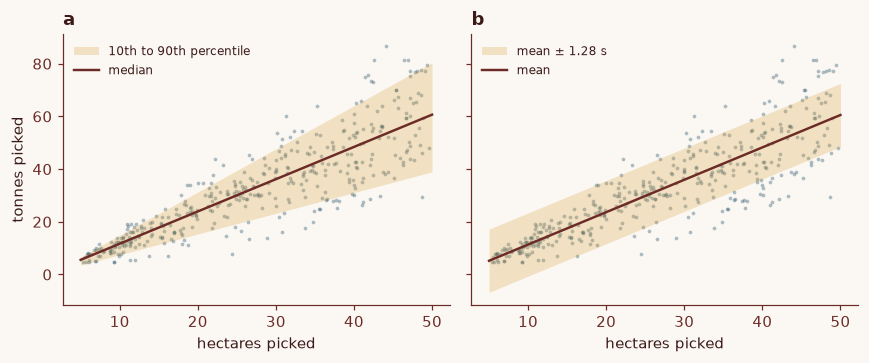

s = 9.35 t, so the mean band is 24.0 t wide everywhere
quantile band width: 10 ha 7.4 t, 45 ha 37.2 t


In [3]:
c_data, c_band, c_line, c_true = fallcolor.palette.discrete("default")
grid = np.linspace(5, 50, 2)[:, None]
s = np.std(tonnes - ols.predict(X), ddof=2)  # residual standard deviation (t)
z = norm.ppf(0.9)  # 1.28: a normal 80% interval is mean +/- z s

fig, axes = plt.subplots(1, 2, figsize=(8, 3.4), sharey=True)
for ax, title in zip(axes, ["a", "b"]):
    ax.scatter(ha, tonnes, s=6, color=c_data, alpha=0.35, lw=0)
    ax.set_xlabel("hectares picked")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
lo, mid, hi = (qr[tau].predict(grid) for tau in TAUS)
axes[0].fill_between(grid[:, 0], lo, hi, color=c_band, alpha=0.25, lw=0, label="10th to 90th percentile")
axes[0].plot(grid[:, 0], mid, color=c_line, lw=1.6, label="median")
mean = ols.predict(grid)
axes[1].fill_between(grid[:, 0], mean - z * s, mean + z * s, color=c_band, alpha=0.25, lw=0, label="mean ± 1.28 s")
axes[1].plot(grid[:, 0], mean, color=c_line, lw=1.6, label="mean")
axes[0].set_ylabel("tonnes picked")
for ax in axes:
    ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()
print(f"s = {s:.2f} t, so the mean band is {2 * z * s:.1f} t wide everywhere")
print("quantile band width: " + ", ".join(f"{h} ha {qr[0.9].predict([[h]])[0] - qr[0.1].predict([[h]])[0]:.1f} t" for h in (10, 45)))

<strong>Figure 1 | Quantile lines fan out with the data; a mean $\pm$ constant band cannot.</strong> 400 synthetic weeks of harvest against area picked. <strong>a</strong>, Linear quantile regression at $\tau = 0.1$, $0.5$ and $0.9$. <strong>b</strong>, The least-squares line $\pm 1.28\,s$, where $s$ is the residual standard deviation and $1.28 = z_{0.9}$, the usual 80% interval when errors are normal with a common spread.

The constant band is $2 \times 1.28 \times 9.35 = 24.0\text{ t}$ wide everywhere. It is too wide for small blocks, where it even reaches below zero tonnes, and too narrow for large ones. The quantile band is $7.4\text{ t}$ wide at $10\text{ ha}$ and $37.2\text{ t}$ at $45\text{ ha}$. That is the "common spread" assumption in the least-squares module's table failing, and quantile regression does not need it: each line is fitted separately, so the band can widen, narrow or skew wherever the data do.

## Nonlinear quantiles with gradient boosting

A straight line cannot follow a season. The second synthetic data set has 60 fields, each picked for 30 weeks. Volume follows a bell-shaped curve peaking in week 14, scaled by a field size that varies from field to field, with multiplicative noise, so the spread is largest at the peak. Each row carries three features: the week, last week's tonnes from the same field (the lag table of [Gradient boosting for tabular time series](../forecast/gradient_boosting_for_time_series.ipynb)), and rainfall, which in this generator has no effect at all. Whole fields are held out, so the test asks how the model does on fields it has never seen.

In [4]:
WEEKS, FIELDS = 30, 60


def season():
    """Synthetic weekly tonnes for 60 fields: a peak at week 14, scaled by field size, with
    multiplicative noise so the spread grows with the level. Rain is generated but has no effect."""
    week = np.tile(np.arange(1, WEEKS + 1), FIELDS)
    size = np.repeat(rng.lognormal(0, 0.3, FIELDS), WEEKS)
    level = 40 * size * np.exp(-0.5 * ((week - 14) / 5) ** 2)
    d = pd.DataFrame({"field": np.repeat(np.arange(FIELDS), WEEKS), "week": week,
                      "tonnes": level * rng.lognormal(0, 0.3, week.size), "rain_mm": rng.gamma(1, 10, week.size)})
    d["last_week"] = d.groupby("field")["tonnes"].shift(1)
    return d.dropna()


d = season()
FEATURES = ["week", "last_week", "rain_mm"]
train, test = d[d["field"] < 40], d[d["field"] >= 40]  # hold out whole fields, not random rows
print(f"train {len(train)} rows from {train['field'].nunique()} fields | held out {len(test)} rows from {test['field'].nunique()} fields")

train 1160 rows from 40 fields | held out 580 rows from 20 fields


Gradient boosting takes the pinball loss in place of squared error: `HistGradientBoostingRegressor(loss="quantile", quantile=q)` in scikit-learn, or `objective="quantile"` with `alpha=q` in LightGBM. Each model targets one quantile, so a fan of seven quantiles is seven models, fitted independently. Nothing makes the 0.9 model's prediction exceed the 0.75 model's, and on new rows it sometimes does not:

In [5]:
QS = (0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95)


def fit_quantiles(**params):
    return {q: HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=0, **params)
            .fit(train[FEATURES], train["tonnes"]) for q in QS}


def predict(models, rows):
    return np.column_stack([models[q].predict(rows[FEATURES]) for q in QS])  # one column per quantile


default = fit_quantiles()
P = predict(default, test)
crossed = np.diff(P, axis=1) < 0  # True where a higher quantile sits below the one before it
print(f"held-out rows with at least one crossing: {crossed.any(axis=1).sum()} of {len(test)}")
print(dict(zip([f"{a}>{b}" for a, b in zip(QS, QS[1:])], crossed.sum(axis=0).tolist())))

held-out rows with at least one crossing: 290 of 580
{'0.05>0.1': 87, '0.1>0.25': 53, '0.25>0.5': 36, '0.5>0.75': 27, '0.75>0.9': 46, '0.9>0.95': 124}


Half the held-out rows have at least one pair of quantiles out of order, a **quantile crossing**. Most are between neighbours in the tails, $0.05$ and $0.1$, or $0.9$ and $0.95$, where the true quantiles are closest together and each fit rests on a handful of extreme points. A crossed forecast is not merely ugly: "a 90% chance of at most 40 tonnes, and a 95% chance of at most 38" is incoherent, and anything downstream that interpolates between quantiles will misbehave.

The standard repair is to sort each row's predictions. Chernozhukov, Fernández-Val and Galichon showed that this rearrangement brings an estimated quantile curve closer to the true one in finite samples[^3]. It costs one line, and here it lowers the held-out pinball loss slightly:

In [6]:
def total_pinball(y, P):
    return sum(mean_pinball_loss(y, P[:, i], alpha=q) for i, q in enumerate(QS))


P_sorted = np.sort(P, axis=1)
print(f"summed pinball loss on held-out rows: as fitted {total_pinball(test['tonnes'], P):.3f} t, "
      f"sorted {total_pinball(test['tonnes'], P_sorted):.3f} t")

summed pinball loss on held-out rows: as fitted 13.769 t, sorted 13.708 t


Sorting treats the symptom. Fewer, more widely spaced quantiles cross less, and so does a less flexible model, which the next section needs for a different reason.

## Checking the ranges on held-out data

The defining property of a quantile forecast is testable: on new data, a fraction $\tau$ of outcomes should fall below $\hat{q}_\tau$, and a fraction $0.9 - 0.1 = 0.8$ inside $[\hat{q}_{0.1}, \hat{q}_{0.9}]$. That fraction is the **empirical coverage**. Check it overall, and then within groups, because a band can be right on average and wrong almost everywhere.

The linear example shows how. Draw 3,000 fresh weeks from the same generator and count how many land inside each 80% interval, by size of area picked:

In [7]:
ha_new, tonnes_new = harvest(3000)  # fresh weeks from the same generator
lo, hi = (qr[tau].predict(ha_new[:, None]) for tau in (0.1, 0.9))
mean = ols.predict(ha_new[:, None])
inside = pd.DataFrame(
    {
        "quantile regression": (tonnes_new >= lo) & (tonnes_new <= hi),
        "mean ± 1.28 s": np.abs(tonnes_new - mean) <= z * s,
    }
)
by_size = inside.groupby(pd.cut(ha_new, [5, 20, 35, 50], include_lowest=True), observed=True).mean()
by_size.index = ["5-20 ha", "20-35 ha", "35-50 ha"]
by_size.loc["all"] = inside.mean()
by_size.round(3)  # share of new weeks inside each 80% interval

,quantile regression,mean ± 1.28 s
5-20 ha,0.758,0.994
20-35 ha,0.824,0.849
35-50 ha,0.830,0.651
all,0.803,0.836


Overall, both bands look acceptable: $80.3\%$ and $83.6\%$. Split by area, the constant band covers $99.4\%$ of small weeks and $65.1\%$ of large ones, wrong in opposite directions in a way the average hides. The quantile band stays between $75.8\%$ and $83.0\%$ in every third.

For the boosted models, compare coverage on the rows they were fitted to with coverage on the held-out fields. A second set of models is fitted with shallower trees (`max_depth=2`), at least 100 rows per leaf and a smaller learning rate:

In [8]:
regularised = fit_quantiles(max_depth=2, min_samples_leaf=100, learning_rate=0.05)


def report(models, rows):
    P = np.sort(predict(models, rows), axis=1)
    y = rows["tonnes"].to_numpy()
    row = {f"below q{q}": (y <= P[:, i]).mean() for i, q in enumerate(QS) if q in (0.1, 0.5, 0.9)}
    row["inside 10-90"] = ((y >= P[:, 1]) & (y <= P[:, 5])).mean()
    return row


pd.DataFrame(
    {
        ("default", "train"): report(default, train),
        ("default", "held out"): report(default, test),
        ("regularised", "train"): report(regularised, train),
        ("regularised", "held out"): report(regularised, test),
    }
).T.round(3)

below q0.1  below q0.5  below q0.9  inside 10-90
default     train          0.125       0.499       0.884         0.759
            held out       0.141       0.429       0.786         0.645
regularised train          0.087       0.522       0.917         0.830
            held out       0.090       0.452       0.874         0.784

The default models cover $75.9\%$ of their training rows and $64.5\%$ of the held-out fields: their deep trees fit the noise in the training fields, so their intervals are too narrow for fields they have not seen. The regularised models cover $83.0\%$ in training and $78.4\%$ held out. Only the held-out figure counts; in-sample coverage says almost nothing, because minimising the pinball loss pushes the training fraction towards $\tau$ however badly the model generalises.

Two cautions about the held-out number itself. If the 580 rows were independent, its standard error would be $\sqrt{0.8 \times 0.2 / 580} = 0.017$. They are not: weeks from one field share a field size, and coverage varies a great deal from field to field.

In [9]:
P_reg = predict(regularised, test)
print(f"regularised: held-out rows with a crossing {(np.diff(P_reg, axis=1) < 0).any(axis=1).sum()} of {len(test)}")
P_reg = np.sort(P_reg, axis=1)
per_field = test.assign(inside=(test["tonnes"] >= P_reg[:, 1]) & (test["tonnes"] <= P_reg[:, 5])).groupby("field")["inside"].mean()
print(f"10-90 coverage by held-out field: {per_field.min():.2f} to {per_field.max():.2f}")

regularised: held-out rows with a crossing 108 of 580
10-90 coverage by held-out field: 0.55 to 0.93


Coverage by held-out field runs from $55\%$ to $93\%$, so 20 fields pin the overall figure down less tightly than 580 rows suggest. Regularising also cut crossings from 290 rows to 108. And the median still sits a little high on these fields ($45.2\%$ below, against $50\%$), a reminder to check each quantile, not only the interval. Figure 2 shows what the forecasts look like for two of the held-out fields.

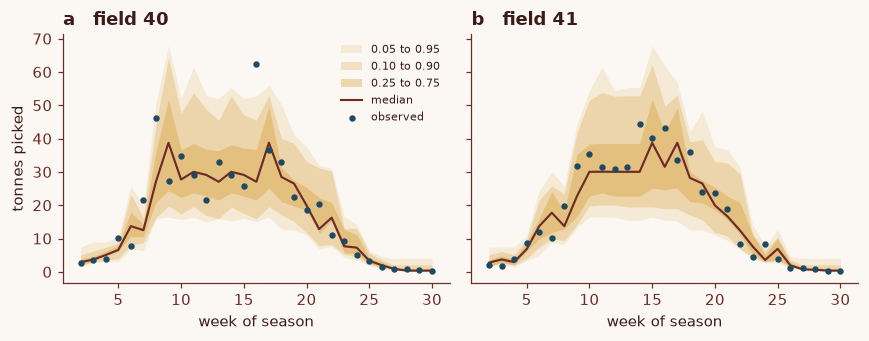

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, f, title in zip(axes, (40, 41), "ab"):
    m = (test["field"] == f).to_numpy()
    w = test.loc[m, "week"]
    for (i, j), alpha in zip([(0, 6), (1, 5), (2, 4)], (0.15, 0.25, 0.35)):
        ax.fill_between(w, P_reg[m, i], P_reg[m, j], color=c_band, alpha=alpha, lw=0,
                        label=f"{QS[i]:.2f} to {QS[j]:.2f}")
    ax.plot(w, P_reg[m, 3], color=c_line, lw=1.4, label="median")
    ax.scatter(w, test.loc[m, "tonnes"], s=10, color=c_data, zorder=3, label="observed")
    ax.set_title(f"{title}   field {f}", loc="left", fontweight="bold")
    ax.set_xlabel("week of season")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("tonnes picked")
axes[0].legend(frameon=False, fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()

<strong>Figure 2 | One-week-ahead quantile forecasts widen where the volume is large.</strong> Two held-out synthetic fields. Each week's fan comes from the regularised, sorted boosted models, using that field's observed tonnes from the week before. Shaded bands, from light to dark: 5th to 95th, 10th to 90th and 25th to 75th percentiles.

When tuning cannot bring held-out coverage to target, the remaining option is to adjust the intervals using held-out errors, which is the subject of the next module in this part.

## Key takeaways

- Least squares models the conditional mean. Quantile regression models a conditional quantile by minimising the pinball loss $L_\tau = \max(\tau u, (\tau - 1)u)$ of the residual $u$, which places a fraction $\tau$ of the training points below the fit.
- Fitting each quantile separately lets the interval widen or narrow with the features. A mean $\pm$ constant band cannot, and here it covered $99\%$ of small weeks and $65\%$ of large ones while averaging $84\%$.
- Use `QuantileRegressor(quantile=tau, alpha=0)` for linear models and `loss="quantile"` (scikit-learn) or `objective="quantile"` (LightGBM) for boosted trees, one model per quantile.
- Independently fitted quantiles cross. Sort each row's predictions; it is cheap and, if anything, improves the fit.
- Judge quantiles on held-out data only, by the fraction below each $\hat{q}_\tau$ and inside each interval, overall and by group. A boosted model covered $76\%$ of its training rows and $64.5\%$ of new fields before it was regularised.

## References

[^1]: Koenker, R. & Bassett, G. Regression quantiles. *Econometrica* **46**, 33 (1978). https://doi.org/10.2307/1913643
[^2]: Koenker, R. & Hallock, K. F. Quantile regression. *J. Econ. Perspect.* **15**, 143–156 (2001). https://doi.org/10.1257/jep.15.4.143
[^3]: Chernozhukov, V., Fernández-Val, I. & Galichon, A. Quantile and probability curves without crossing. *Econometrica* **78**, 1093–1125 (2010). https://doi.org/10.3982/ECTA7880

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/pinball-loss-and-quantiles.html"><span>Previous</span>Pinball loss and quantiles</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/many-series/forecasting_many_series.html"><span>Next</span>Forecasting many series at once</a></div>
<!-- CURRICULUM_FOOTER_END -->